In [ ]:
!pip uninstall -y opencv -python opencv -python-headless opencv-contib-python
!pip install opencv-python-headless==4.10.0.84



Usage:   
  pip3 uninstall [options] <package> ...
  pip3 uninstall [options] -r <requirements file> ...

no such option: -p
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 20.4 MB/s eta 0:00:00


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
from PIL import Image

import cv2
import os

import tensorflow as tf
from tensorflow import keras
from keras import layers

from  google.colab.patches import cv2_imshow

import warnings
warnings.filterwarnings("ignore")

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving emojis.zip to emojis.zip


In [ ]:
!unzip -o emojis.zip

Archive:  emojis.zip
   creating: emojis/
  inflating: emojis/angry.jpg        
  inflating: emojis/disgust.jpg      
  inflating: emojis/fear.jpg         
  inflating: emojis/happy.jpg        
  inflating: emojis/neutral.jpg      
  inflating: emojis/sad.jpg          
  inflating: emojis/surprise.jpg     
  inflating: emojis/znone.jpg        


In [ ]:
!ls emojis

angry.jpg    fear.jpg	neutral.jpg  surprise.jpg
disgust.jpg  happy.jpg	sad.jpg      znone.jpg


In [ ]:
import kagglehub

path = kagglehub.dataset_download("msambare/fer2013")

print("Path: ", path)

Using Colab cache for faster access to the 'fer2013' dataset.
Path:  /kaggle/input/fer2013


In [ ]:
train_dir = path + "/train"
test_dir = path + "/test"

print("Train Dir: ", train_dir)
print("Test Dir: ", test_dir)

Train Dir:  /kaggle/input/fer2013/train
Test Dir:  /kaggle/input/fer2013/test


In [ ]:
path = train_dir

classes = os.listdir(path)

classes

['surprise', 'fear', 'angry', 'neutral', 'sad', 'disgust', 'happy']

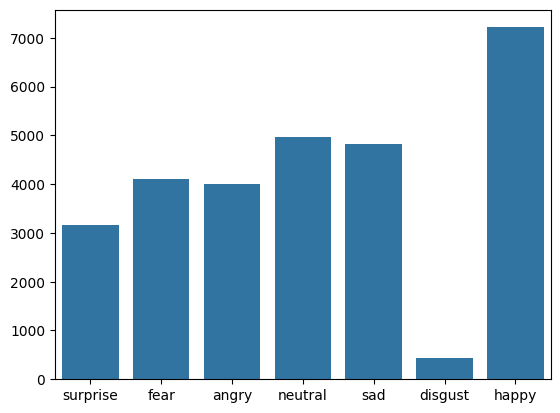

In [ ]:
count = []

for cat in classes:
  count.append(len(os.listdir(f'{path}/{cat}')))

sb.barplot(x = classes, y = count)
plt.show()

In [ ]:
train_gen = keras.utils.image_dataset_from_directory(
    train_dir,
    image_size = (48,48),
    batch_size = 64,
    color_mode = 'grayscale',
    label_mode = 'categorical'
)

val_gen = keras.utils.image_dataset_from_directory(
    test_dir,
    image_size = (48,48),
    batch_size = 64,
    color_mode = 'grayscale',
    label_mode = 'categorical'
)

data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.05)
])

Found 28709 files belonging to 7 classes.
Found 7178 files belonging to 7 classes.


In [ ]:
emotions = list(train_gen.class_names)
emotions

['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

In [ ]:
model = keras.models.Sequential([
    data_augmentation,
    layers.Rescaling(1./255),

    # Block 1
    layers.Conv2D(32, (3,3), padding = 'same', activation = 'relu'),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3,3), padding = 'same', activation = 'relu'),
    layers.MaxPooling2D(2,2),
    layers.Dropout(0.25),

    # Block 2
    layers.Conv2D(64, (3,3), padding = 'same', activation = 'relu'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3,3), padding = 'same', activation = 'relu'),
    layers.MaxPooling2D(2,2),
    layers.Dropout(0.25),

    # Block 3
    layers.Conv2D(128, (3,3), padding = 'same', activation = 'relu'),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3,3), padding = 'same', activation = 'relu'),
    layers.MaxPooling2D(2,2),
    layers.Dropout(0.25),

    # Classifier
    layers.Flatten(),
    layers.Dense(128, activation = 'relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),

    layers.Dense(7, activation = 'softmax')

])

In [ ]:
model.compile(
    optimizer = 'adam',
    loss = 'categorical_crossentropy',
    metrics = ['accuracy']
)

In [ ]:
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

es = EarlyStopping(
    monitor = 'val_accuracy',
    patience = 5,
    restore_best_weights = True,
    verbose = 1
)

lr = ReduceLROnPlateau(
    monitor = 'val_loss',
    patience = 2,
    factor = 0.5,
    min_lr = 1e-6,
    verbose = 1
)

In [ ]:
class_weights = {
    0: 1.0,
    1: 3.0,
    2: 1.0,
    3: 0.7,
    4: 0.9,
    5: 0.9,
    6: 1.2
}

In [ ]:
class_weights = {
    0: (),
    1: 3.0,
    2: 1.0,
    3: 0.7,
    4: 0.9,
    5: 0.9,
    6: 1.2
}

In [ ]:
history = model.fit(
    train_gen,
    validation_data = val_gen,
    epochs = 50,
    class_weight = class_weights,
    verbose = 1,
    callbacks = [es, lr]
)

Epoch 1/50
449/449 ━━━━━━━━━━━━━━━━━━━━ 17s 38ms/step - accuracy: 0.5285 - loss: 1.2229 - val_accuracy: 0.5632 - val_loss: 1.1581 - learning_rate: 0.0010
Epoch 2/50
449/449 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step - accuracy: 0.5369 - loss: 1.2012 - val_accuracy: 0.5488 - val_loss: 1.1811 - learning_rate: 0.0010
Epoch 3/50
448/449 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.5432 - loss: 1.1828
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
449/449 ━━━━━━━━━━━━━━━━━━━━ 17s 39ms/step - accuracy: 0.5483 - loss: 1.1717 - val_accuracy: 0.5078 - val_loss: 1.2926 - learning_rate: 0.0010
Epoch 4/50
449/449 ━━━━━━━━━━━━━━━━━━━━ 18s 40ms/step - accuracy: 0.5672 - loss: 1.1252 - val_accuracy: 0.5836 - val_loss: 1.1019 - learning_rate: 5.0000e-04
Epoch 5/50
449/449 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step - accuracy: 0.5747 - loss: 1.1019 - val_accuracy: 0.5954 - val_loss: 1.0655 - learning_rate: 5.0000e-04
Epoch 6/50
449/449 ━━━━━━━━━━━━━━━━━━━━ 17s 38ms/step - accuracy: 0.58

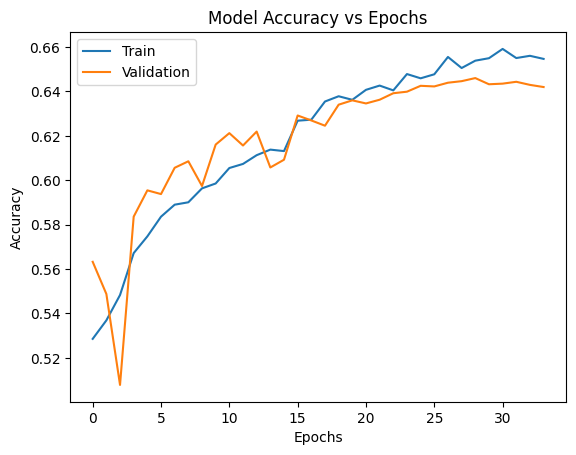

In [ ]:
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])

plt.title("Model Accuracy vs Epochs")
plt.ylabel("Accuracy")
plt.xlabel("Epochs")
plt.legend(["Train", "Validation"], loc = "upper left")
plt.show()

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

predictions = model.predict(val_gen)

y_pred = np.argmax(predictions, axis = 1)
y_true = np.concatenate([np.argmax(labels.numpy(), axis = 1) for images, labels in val_gen])

print(classification_report(
    y_true,
    y_pred,
    target_names = val_gen.class_names
))

113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step
              precision    recall  f1-score   support

       angry       0.11      0.12      0.11       958
     disgust       0.01      0.01      0.01       111
        fear       0.13      0.09      0.11      1024
       happy       0.25      0.25      0.25      1774
     neutral       0.18      0.23      0.20      1233
         sad       0.17      0.15      0.16      1247
    surprise       0.12      0.12      0.12       831

    accuracy                           0.17      7178
   macro avg       0.14      0.14      0.14      7178
weighted avg       0.17      0.17      0.17      7178



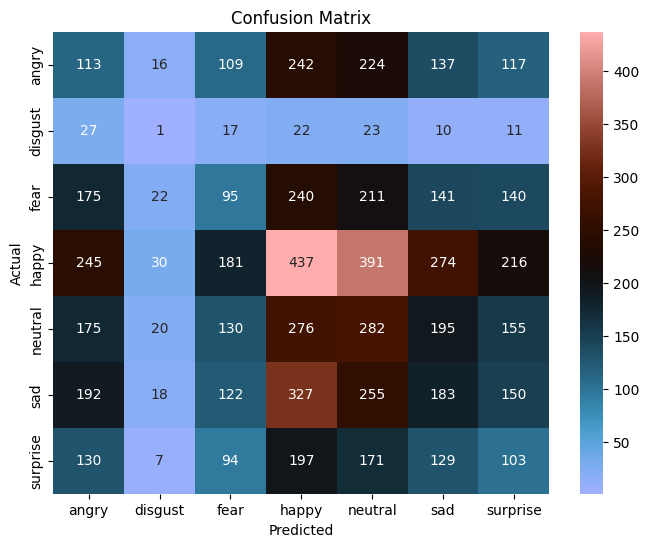

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))

sb.heatmap(
    cm,
    cmap = 'berlin',
    annot = True,
    fmt = 'd',
    xticklabels = val_gen.class_names,
    yticklabels = val_gen.class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


In [ ]:
def plot_image(img, emoji):

  wmin = 256
  hmin = 256

  emoji = cv2.resize(emoji, (wmin, hmin))
  img = cv2.resize(img, (wmin, hmin))

  cv2_imshow(img)
  cv2_imshow(emoji)

In [ ]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

def take_photo(filename='photo.jpg', quality=0.8):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);

      const video = document.createElement('video');
      video.style.display = 'block';
      video.style.transform = 'scaleX(-1)';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      // Resize the output to fit the video element.
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      // Wait for Capture to be clicked.
      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)
  data = eval_js('takePhoto({})'.format(quality))
  binary = b64decode(data.split(',')[1])
  with open(filename, 'wb') as f:
    f.write(binary)
  return filename

<IPython.core.display.Javascript object>

Saved to photo.jpg


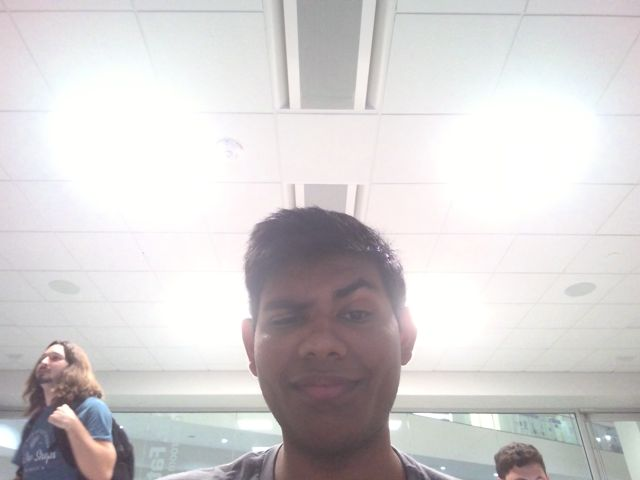

In [ ]:
from IPython.display import Image
try:
  filename = take_photo()
  print('Saved to {}'.format(filename))

  # Show the image which was just taken.
  display(Image(filename))
except Exception as err:
  # Errors will be thrown if the user does not have a webcam or if they do not
  # grant the page permission to access it.
  print(str(err))

In [ ]:
cascade_path = cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
face_cascade = cv2.CascadeClassifier(cascade_path)

filename = take_photo()

frame = cv2.imread(filename)

img = cv2.resize(frame, (256,256))

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

faces = face_cascade.detectMultiScale(gray)

if len(faces) > 0:

  for(x, y, w, h) in faces:

    face = gray[y:y+h, x:x+w]

    face = cv2.resize(face, (48,48))

    face = np.expand_dims(face, axis=-1)
    face = np.expand_dims(face, axis=0)

    pred = model.predict(face, verbose = 0)

    idx = pred.argmax(axis=-1) [0]

    emoji_path = f'emojis/{emotions[idx]}.jpg'
    emoj = cv2.imread(emoji_path)

    plot_image(img, emoj)

else:

  emoj = cv2.imread('emojis/znone.jpg')
  plot_image(img, emoj)
  print("No face detected")